In [2]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime, timedelta
import time as py_time
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split, KFold

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

from tinkoff.invest import Client, CandleInterval, RequestError
from tinkoff.invest.utils import now, quotation_to_decimal

TINKOFF_API_TOKEN = "t.He-UEc5Mfe_E2w9CVSlZsCrqyoFacn52Yut_rwdsK8EclvfaxLlju33-26Z2cW22w0dDKNK0cNpxsyXLSGZv-g"

INSTRUMENT_FIGI = "BBG004730N88"
DAYS_HISTORY = 10
CANDLE_TIMEFRAME = CandleInterval.CANDLE_INTERVAL_10_MIN
N_STEPS_IN = 814
N_STEPS_OUT = 100
FEATURE_COLUMN = 'close'

2025-05-10 23:58:25.857289: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [3]:
def get_tinkoff_candles(token, figi, days, interval):
    with Client(token) as client:
        end_dt = now()
        start_dt = end_dt - timedelta(days=days)
        candles = list(client.get_all_candles(figi=figi, from_=start_dt, to=end_dt, interval=interval))
        df = pd.DataFrame([{ 'time': pd.Timestamp(c.time).tz_localize(None),
                             'open': float(quotation_to_decimal(c.open)),
                             'high': float(quotation_to_decimal(c.high)),
                             'low': float(quotation_to_decimal(c.low)),
                             'close': float(quotation_to_decimal(c.close)),
                             'volume': c.volume } for c in candles])
        df = df.set_index('time').sort_index().dropna()
        print("Исходные данные (первые и последние 5 строк):")
        print(pd.concat([df.head(), df.tail()]))
        return df

In [4]:
def prepare_data(df, feature_col):
    values = df[[feature_col]].dropna().values.astype(float)
    return values, df[feature_col]


In [5]:
def split_sequences(data, n_steps_in, n_steps_out):
    X, y = [], []
    for i in range(len(data) - n_steps_in - n_steps_out + 1):
        X.append(data[i:i+n_steps_in])
        y.append(data[i+n_steps_in:i+n_steps_in+n_steps_out])
    return np.array(X), np.array(y)

In [6]:
def build_lstm_model(n_steps_in, n_steps_out):
    model = Sequential()
    model.add(LSTM(75, return_sequences=True, input_shape=(n_steps_in, 1)))
    model.add(Dropout(0.2))
    model.add(LSTM(75))
    model.add(Dropout(0.2))
    model.add(Dense(50, activation='relu'))
    model.add(Dense(n_steps_out))
    model.compile(optimizer='adam', loss='mean_squared_error')
    return model

In [7]:
def plot_predictions(dates, actual, predicted, title):
    plt.figure(figsize=(12, 4))
    plt.plot(dates, actual, label='Actual')
    plt.plot(dates, predicted, label='Predicted')
    plt.title(title)
    plt.xlabel("Дата и время")
    plt.ylabel("Цена")
    plt.xticks(rotation=45)
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

In [8]:
def cross_validate_lstm(X, y, scaler, n_splits=4):
    best_mse = float('inf')
    best_model = None
    best_history = None

    kf = KFold(n_splits=n_splits, shuffle=True, random_state=42)
    for fold, (train_idx, val_idx) in enumerate(kf.split(X)):
        print(f"--- Обучение модели fold {fold+1} ---")
        model = build_lstm_model(N_STEPS_IN, N_STEPS_OUT)

        X_train, y_train = X[train_idx], y[train_idx]
        X_val, y_val = X[val_idx], y[val_idx]

        history = model.fit(X_train, y_train, validation_data=(X_val, y_val),
                            epochs=50, batch_size=32, verbose=0,
                            callbacks=[EarlyStopping(monitor='val_loss', patience=5)])

        preds = model.predict(X_val)
        preds_inv = scaler.inverse_transform(preds.squeeze())
        y_val_inv = scaler.inverse_transform(y_val.squeeze())


        mse = mean_squared_error(y_val_inv[:, 0], preds_inv[:, 0])
        print(f"MSE fold {fold+1}: {mse:.6f}")

        print("\nСравнение фактических и предсказанных значений:")
        for i in range(len(y_val_inv)):
            print(f"{i}: Факт = {y_val_inv[i][0]:.4f}, Прогноз = {preds_inv[i][0]:.4f}")

        time_indexes = pd.date_range(start=pd.Timestamp.now(), periods=len(preds_inv), freq='T')
        plot_predictions(time_indexes, y_val_inv[:, 0], preds_inv[:, 0], title=f"Fold {fold+1} Prediction")

        if mse < best_mse:
            best_mse = mse
            best_model = model
            best_history = history

    print(f"\nВыбрана лучшая модель с MSE: {best_mse:.6f}")
    return best_model

In [9]:
def final_test(model, X_test, y_test, scaler, original_df, window_size):
    preds = model.predict(X_test)

    # Используем только первое значение прогноза (например, следующий момент)
    y_test_1step = y_test[:, 0]
    preds_1step = preds[:, 0]

    y_test_2d = y_test_1step.reshape(-1, 1)
    preds_2d = preds_1step.reshape(-1, 1)

    y_test_inv = scaler.inverse_transform(y_test_2d)
    preds_inv = scaler.inverse_transform(preds_2d)

    dates = original_df.index[-len(y_test):][:len(y_test_inv)]

    result_df = pd.DataFrame({
        'datetime': dates,
        'actual_close': y_test_inv.flatten(),
        'predicted_close': preds_inv.flatten()
    }).set_index('datetime')

    print("Сравнение фактических и предсказанных значений:")
    print(result_df)

    plt.figure(figsize=(15, 6))
    plt.plot(result_df.index, result_df['actual_close'], label='Фактическая цена')
    plt.plot(result_df.index, result_df['predicted_close'], label='Прогноз', linestyle='--')
    plt.title("Фактическая и предсказанная цена закрытия")
    plt.xlabel("Дата и время")
    plt.ylabel("Цена")
    plt.xticks(rotation=45)
    plt.grid(True)
    plt.legend()
    plt.tight_layout()
    plt.show()

    mse = mean_squared_error(y_test_inv, preds_inv)
    print(f"\nСреднеквадратичная ошибка (MSE): {mse:.6f}")


Исходные данные (первые и последние 5 строк):
                       open    high     low   close  volume
time                                                       
2025-04-30 23:00:00  306.11  310.00  306.11  308.40     377
2025-04-30 23:10:00  307.56  308.35  307.26  307.84     143
2025-04-30 23:20:00  307.79  307.80  307.26  307.80      69
2025-04-30 23:30:00  306.94  308.40  306.94  308.00     183
2025-04-30 23:40:00  307.40  308.33  307.38  308.00       8
2025-05-10 20:00:00  301.80  302.52  301.66  301.75     784
2025-05-10 20:10:00  301.75  302.28  301.75  302.20     485
2025-05-10 20:20:00  302.30  302.53  301.88  302.53    1137
2025-05-10 20:30:00  302.50  303.50  301.60  302.25    6762
2025-05-10 20:40:00  302.60  303.46  302.41  303.46    1291
--- Обучение модели fold 1 ---


2025-05-10 23:58:30.378353: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)
/home/marcus2tut/.local/lib/python3.11/site-packages/keras/src/layers/rnn/rnn.py:200: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 214ms/step
MSE fold 1: 0.953669

Сравнение фактических и предсказанных значений:
0: Факт = 301.7300, Прогноз = 302.2895
1: Факт = 304.7400, Прогноз = 302.6251
2: Факт = 302.4300, Прогноз = 302.3679
3: Факт = 302.9500, Прогноз = 302.3907
4: Факт = 303.2900, Прогноз = 302.5128
5: Факт = 303.7200, Прогноз = 302.5861
6: Факт = 303.1500, Прогноз = 302.6663
7: Факт = 302.7100, Прогноз = 302.4170
8: Факт = 304.1800, Прогноз = 302.6055
9: Факт = 302.2200, Прогноз = 302.3535
10: Факт = 301.9500, Прогноз = 302.2987
11: Факт = 303.6800, Прогноз = 302.7380
12: Факт = 303.9300, Прогноз = 302.6491
13: Факт = 303.4900, Прогноз = 302.4921
14: Факт = 304.0000, Прогноз = 302.6187
15: Факт = 302.0100, Прогноз = 302.3333
16: Факт = 301.7500, Прогноз = 302.3333
17: Факт = 302.9000, Прогноз = 302.4059
18: Факт = 302.6400, Прогноз = 302.2992
19: Факт = 304.1600, Прогноз = 302.7139
20: Факт = 302.9000, Прогноз = 302.4050
21: Факт = 303.7200, Прогноз = 302.6400
22: Факт = 302.3500, 

/tmp/ipykernel_1419164/3561127231.py:30: FutureWarning: 'T' is deprecated and will be removed in a future version, please use 'min' instead.
  time_indexes = pd.date_range(start=pd.Timestamp.now(), periods=len(preds_inv), freq='T')


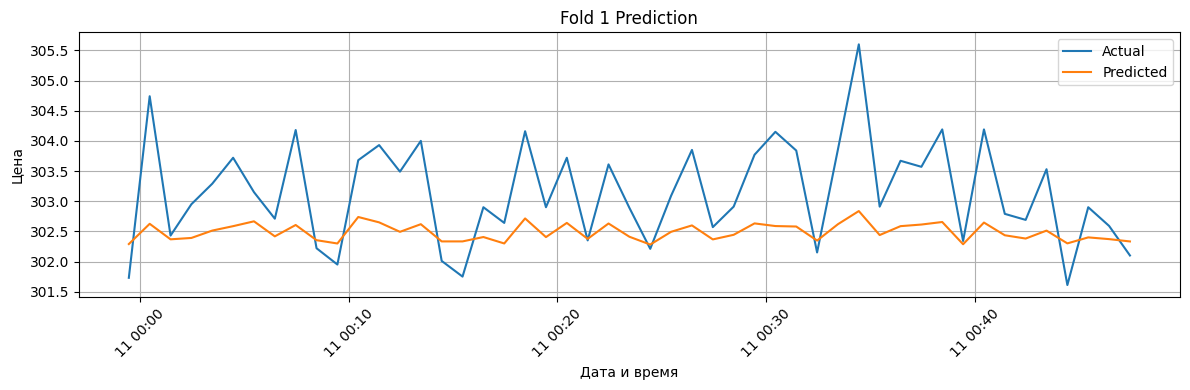

--- Обучение модели fold 2 ---


/home/marcus2tut/.local/lib/python3.11/site-packages/keras/src/layers/rnn/rnn.py:200: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 261ms/step
MSE fold 2: 0.720801

Сравнение фактических и предсказанных значений:
0: Факт = 304.2000, Прогноз = 303.6642
1: Факт = 302.6000, Прогноз = 303.3569
2: Факт = 302.4900, Прогноз = 303.3589
3: Факт = 304.0000, Прогноз = 303.9288
4: Факт = 303.0200, Прогноз = 303.6537
5: Факт = 302.1600, Прогноз = 303.3653
6: Факт = 303.7000, Прогноз = 303.8508
7: Факт = 302.6000, Прогноз = 303.4113
8: Факт = 304.1900, Прогноз = 303.8867
9: Факт = 301.7800, Прогноз = 303.2950
10: Факт = 303.4900, Прогноз = 303.6155
11: Факт = 304.1200, Прогноз = 303.9111
12: Факт = 302.1700, Прогноз = 303.3532
13: Факт = 302.8100, Прогноз = 303.6070
14: Факт = 305.2700, Прогноз = 304.2616
15: Факт = 302.2300, Прогноз = 303.4588
16: Факт = 302.5900, Прогноз = 303.3583
17: Факт = 303.7100, Прогноз = 303.8272
18: Факт = 305.2500, Прогноз = 304.1645
19: Факт = 302.0500, Прогноз = 303.3906
20: Факт = 304.1900, Прогноз = 303.9227
21: Факт = 304.5400, Прогноз = 304.2342
22: Факт = 303.6300, 

/tmp/ipykernel_1419164/3561127231.py:30: FutureWarning: 'T' is deprecated and will be removed in a future version, please use 'min' instead.
  time_indexes = pd.date_range(start=pd.Timestamp.now(), periods=len(preds_inv), freq='T')


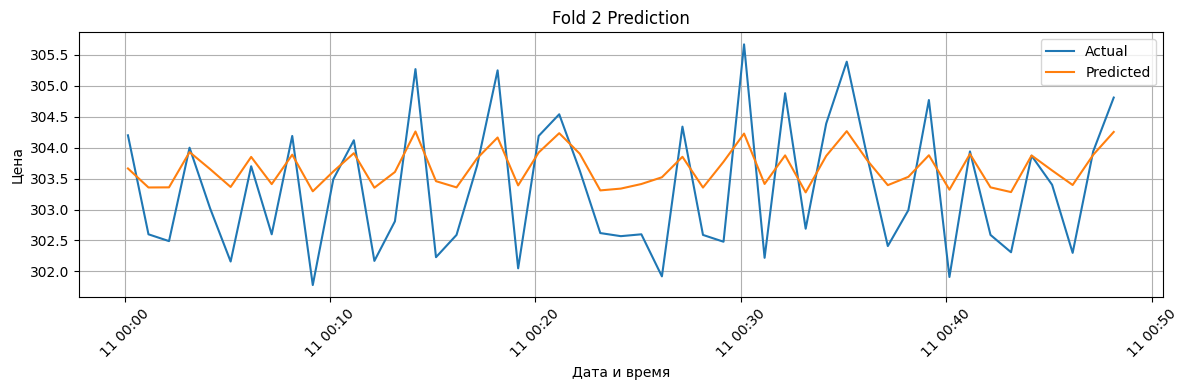

--- Обучение модели fold 3 ---


/home/marcus2tut/.local/lib/python3.11/site-packages/keras/src/layers/rnn/rnn.py:200: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


1/2 ━━━━━━━━━━━━━━━━━━━━ 0s 235ms/stepWARNING:tensorflow:6 out of the last 6 calls to <function TensorFlowTrainer.make_predict_function.<locals>.one_step_on_data_distributed at 0x7fb63c172660> triggered tf.function retracing. Tracing is expensive and the excessive number of tracings could be due to (1) creating @tf.function repeatedly in a loop, (2) passing tensors with different shapes, (3) passing Python objects instead of tensors. For (1), please define your @tf.function outside of the loop. For (2), @tf.function has reduce_retracing=True option that can avoid unnecessary retracing. For (3), please refer to https://www.tensorflow.org/guide/function#controlling_retracing and https://www.tensorflow.org/api_docs/python/tf/function for  more details.
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 223ms/step
MSE fold 3: 0.765321

Сравнение фактических и предсказанных значений:
0: Факт = 302.5900, Прогноз = 303.0292
1: Факт = 302.8800, Прогноз = 303.1199
2: Факт = 303.9600, Прогноз = 303.3046
3: Факт = 302.

/tmp/ipykernel_1419164/3561127231.py:30: FutureWarning: 'T' is deprecated and will be removed in a future version, please use 'min' instead.
  time_indexes = pd.date_range(start=pd.Timestamp.now(), periods=len(preds_inv), freq='T')


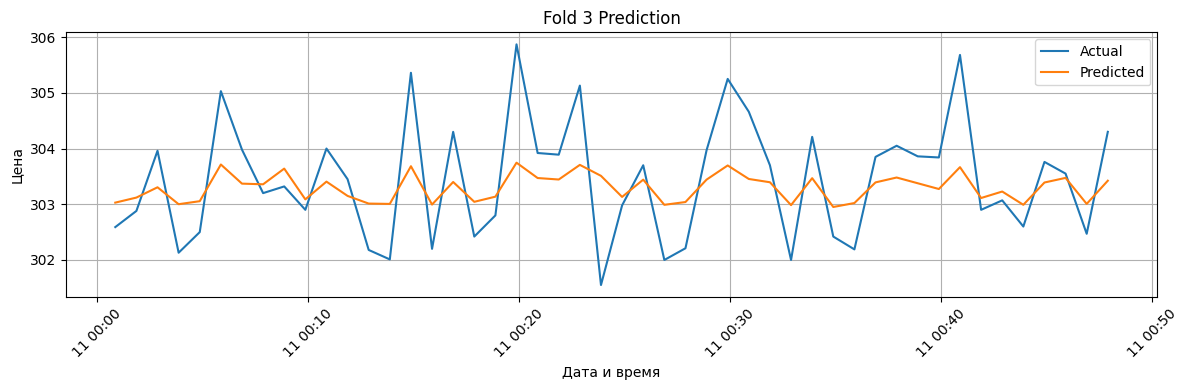

--- Обучение модели fold 4 ---


/home/marcus2tut/.local/lib/python3.11/site-packages/keras/src/layers/rnn/rnn.py:200: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 218ms/step
MSE fold 4: 0.681426

Сравнение фактических и предсказанных значений:
0: Факт = 304.4400, Прогноз = 303.7614
1: Факт = 304.0000, Прогноз = 303.7667
2: Факт = 303.3400, Прогноз = 303.5393
3: Факт = 303.8800, Прогноз = 303.7341
4: Факт = 302.3600, Прогноз = 303.3838
5: Факт = 302.5900, Прогноз = 303.3804
6: Факт = 302.6300, Прогноз = 303.3998
7: Факт = 302.6600, Прогноз = 303.8040
8: Факт = 304.0000, Прогноз = 303.7299
9: Факт = 302.1000, Прогноз = 303.4021
10: Факт = 303.4800, Прогноз = 303.5742
11: Факт = 302.8100, Прогноз = 303.5606
12: Факт = 304.6600, Прогноз = 303.6171
13: Факт = 304.0700, Прогноз = 303.7856
14: Факт = 303.6000, Прогноз = 303.7289
15: Факт = 302.1400, Прогноз = 303.3446
16: Факт = 304.0000, Прогноз = 303.8155
17: Факт = 302.6000, Прогноз = 303.3575
18: Факт = 303.2100, Прогноз = 303.5507
19: Факт = 303.2900, Прогноз = 303.5281
20: Факт = 303.9500, Прогноз = 303.7456
21: Факт = 303.4800, Прогноз = 303.5095
22: Факт = 302.8500, 

/tmp/ipykernel_1419164/3561127231.py:30: FutureWarning: 'T' is deprecated and will be removed in a future version, please use 'min' instead.
  time_indexes = pd.date_range(start=pd.Timestamp.now(), periods=len(preds_inv), freq='T')


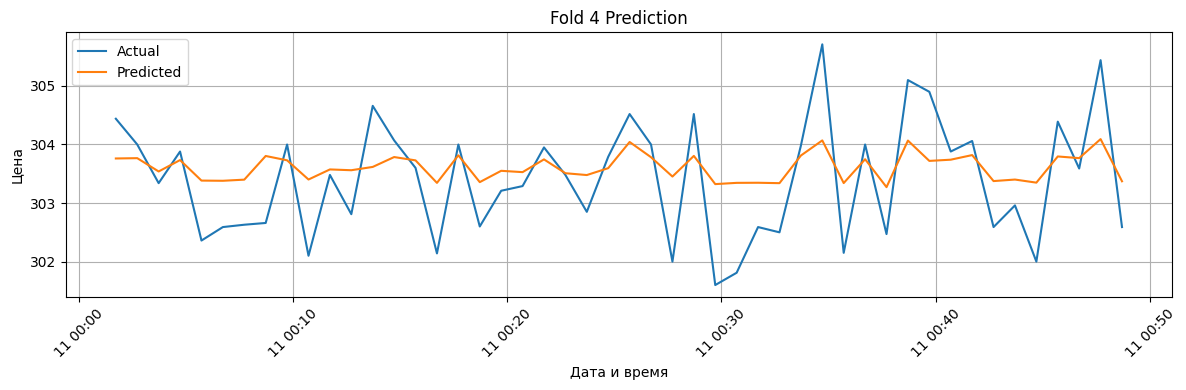


Выбрана лучшая модель с MSE: 0.681426
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 83ms/step
Сравнение фактических и предсказанных значений:
                     actual_close  predicted_close
datetime                                          
2025-05-10 12:40:00        304.01       304.025604
2025-05-10 12:50:00        305.81       304.068542
2025-05-10 13:00:00        303.40       303.594177
2025-05-10 13:10:00        304.00       303.818054
2025-05-10 13:20:00        303.92       303.794434
2025-05-10 13:30:00        304.32       303.750610
2025-05-10 13:40:00        303.55       303.820770
2025-05-10 13:50:00        303.03       303.589203
2025-05-10 14:00:00        305.58       304.073090
2025-05-10 14:10:00        302.60       303.393890
2025-05-10 14:20:00        302.62       303.344238
2025-05-10 14:30:00        304.20       303.785706
2025-05-10 14:40:00        304.11       303.813080
2025-05-10 14:50:00        303.86       303.742676
2025-05-10 15:00:00        302.65       303.341034
2025-05-

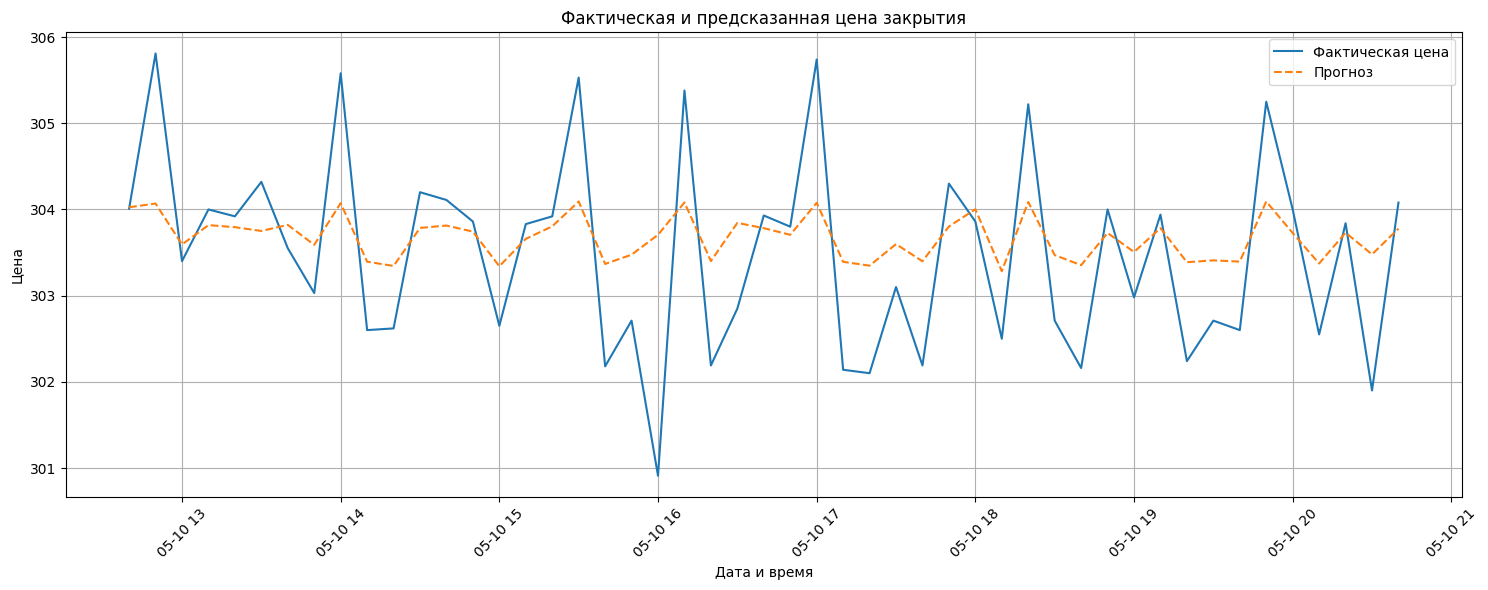


Среднеквадратичная ошибка (MSE): 0.885262


In [10]:
df = get_tinkoff_candles(TINKOFF_API_TOKEN, INSTRUMENT_FIGI, DAYS_HISTORY, CANDLE_TIMEFRAME)
diff_values, original_prices = prepare_data(df, FEATURE_COLUMN)
scaler = MinMaxScaler().fit(diff_values)
scaled = scaler.transform(diff_values)

X_all, y_all = split_sequences(scaled, N_STEPS_IN, N_STEPS_OUT)
X_all = X_all.reshape((X_all.shape[0], X_all.shape[1], 1))

X_trainval, X_test, y_trainval, y_test = train_test_split(X_all, y_all, test_size=0.2, shuffle=True, random_state=42)
best_model = cross_validate_lstm(X_trainval, y_trainval, scaler, n_splits=4)
window_size = 30
final_test(
    best_model,     # обученная модель
    X_test,         # входы тестовой выборки
    y_test,         # правильные ответы (нормализованные)
    scaler,         # объект MinMaxScaler
    df,             # исходный DataFrame с колонками и datetime-индексом
    window_size    # размер скользящего окна, который ты использовал при генерации X
)
